# M2: Resume-Job Matching Baseline Reproduction

This notebook reproduces the baseline methods from our selected research paper:

**Calibrated Resume-Job Matching for Trustworthy LLM-Assisted Recruiter Screening**

The system compares a resume with a job description and predicts one of these classes:

- Good Fit
- Potential Fit
- No Fit

## M2 Objectives

1. Load and study the dataset.
2. Check missing values, labels, and duplicate records.
3. Clean and prepare the text.
4. Reproduce TF-IDF with cosine similarity.
5. Reproduce paired TF-IDF with an SGD classifier.
6. Compare our results with the paper results.

## Main Metric

We use macro-F1 as the main metric because it gives equal importance to all three classes.

## Setup

- Platform: Google Colab
- Runtime: CPU
- Random seed: 42

In [1]:
%pip install -q datasets

import sys
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import datasets

from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
NOTEBOOK_START_TIME = time.time()

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

print("Setup complete")
print(f"Python: {sys.version.split()[0]}")
print(f"datasets: {datasets.__version__}")
print(f"pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"Seaborn: {sns.__version__}")
print(f"Random seed: {SEED}")

Setup complete
Python: 3.13.16
datasets: 4.8.5
pandas: 2.2.3
NumPy: 2.1.3
scikit-learn: 1.6.1
Matplotlib: 3.10.0
Seaborn: 0.13.2
Random seed: 42


In [2]:
DATASET_NAME = "cnamuangtoun/resume-job-description-fit"

dataset = load_dataset(DATASET_NAME)

print(f"Dataset: {DATASET_NAME}")
print(dataset)

for split_name, split_data in dataset.items():
    print(f"{split_name}: {len(split_data):,} rows")

train.csv: reconstructing file:   0%|          |  0.00B / 53.4MB            

train.csv: downloading bytes:           |  0.00B            

test.csv: reconstructing file:   0%|          |  0.00B / 15.2MB            

test.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/6241 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1759 [00:00<?, ? examples/s]

Dataset: cnamuangtoun/resume-job-description-fit
DatasetDict({
    train: Dataset({
        features: ['resume_text', 'job_description_text', 'label'],
        num_rows: 6241
    })
    test: Dataset({
        features: ['resume_text', 'job_description_text', 'label'],
        num_rows: 1759
    })
})
train: 6,241 rows
test: 1,759 rows


In [3]:
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nColumns:", train_df.columns.tolist())
print("\nData types:")
print(train_df.dtypes)

print("\nTraining sample:")
display(train_df.head(3))

Training shape: (6241, 3)
Test shape: (1759, 3)

Columns: ['resume_text', 'job_description_text', 'label']

Data types:
resume_text             object
job_description_text    object
label                   object
dtype: object

Training sample:


,resume_text,job_description_text,label
0,SummaryHighly motivated Sales Associate with extensive customer service and sales experience. Outgoing sales profess...,Net2Source Inc. is an award-winning total workforce solutions company recognized by Staffing Industry Analysts for o...,No Fit
1,Professional SummaryCurrently working with Caterpillar as an contract employee Active in several NPI and CPI project...,At Salas OBrien we tell our clients that were engineered for impact. This passion for making a difference applies ju...,No Fit
2,"SummaryI started my construction career in June of 2017 in Jacksonville, Florida as an Electrical Apprentice working...",Schweitzer Engineering Laboratories (SEL) Infrastructure Defense Division seeks a talented individual for a cybersec...,No Fit


In [4]:
label_order = ["Good Fit", "Potential Fit", "No Fit"]

all_labels = sorted(
    set(train_df["label"].dropna()) | set(test_df["label"].dropna())
)

print("Labels found:", all_labels)

label_counts = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).reindex(label_order).fillna(0).astype(int)

label_counts["Total"] = label_counts["Train"] + label_counts["Test"]
label_counts["Total (%)"] = (
    label_counts["Total"] / label_counts["Total"].sum() * 100
).round(2)

display(label_counts)

Labels found: ['Good Fit', 'No Fit', 'Potential Fit']


,Train,Test,Total,Total (%)
label,,,,
Good Fit,1542,458,2000,25.0
Potential Fit,1556,444,2000,25.0
No Fit,3143,857,4000,50.0


In [5]:
def missing_value_summary(dataframe):
    missing = dataframe.isna().sum()
    empty = dataframe.apply(
        lambda column: column.dropna().astype(str).str.strip().eq("").sum()
    )

    return pd.DataFrame({
        "Missing values": missing,
        "Empty values": empty,
        "Total affected": missing + empty
    })

missing_summary = pd.concat(
    {
        "Train": missing_value_summary(train_df),
        "Test": missing_value_summary(test_df)
    },
    names=["Split", "Column"]
)

display(missing_summary)

Missing values  Empty values  Total affected
Split Column                                                            
Train resume_text                        0             0               0
      job_description_text               0             0               0
      label                              0             0               0
Test  resume_text                        0             0               0
      job_description_text               0             0               0
      label                              0             0               0

In [6]:
PAIR_COLUMNS = ["resume_text", "job_description_text"]

def find_duplicate_pairs(dataframe):
    groups = (
        dataframe.groupby(PAIR_COLUMNS, dropna=False)
        .agg(
            row_count=("label", "size"),
            unique_labels=("label", "nunique"),
            labels=("label", lambda values: sorted(values.unique()))
        )
        .reset_index()
    )
    return groups[groups["row_count"] > 1].copy()

train_duplicate_groups = find_duplicate_pairs(train_df)
test_duplicate_groups = find_duplicate_pairs(test_df)

duplicate_summary = pd.DataFrame({
    "Train": [
        len(train_duplicate_groups),
        train_duplicate_groups["row_count"].sum(),
        (train_duplicate_groups["unique_labels"] > 1).sum(),
        (train_duplicate_groups["unique_labels"] == 1).sum()
    ],
    "Test": [
        len(test_duplicate_groups),
        test_duplicate_groups["row_count"].sum(),
        (test_duplicate_groups["unique_labels"] > 1).sum(),
        (test_duplicate_groups["unique_labels"] == 1).sum()
    ]
}, index=[
    "Duplicate groups",
    "Rows in duplicate groups",
    "Conflicting-label groups",
    "Same-label groups"
])

display(duplicate_summary)

print("\nTraining duplicate-group details:")
display(
    train_duplicate_groups[
        ["row_count", "unique_labels", "labels"]
    ].reset_index(drop=True)
)

,Train,Test
Duplicate groups,7,0
Rows in duplicate groups,14,0
Conflicting-label groups,6,0
Same-label groups,1,0



Training duplicate-group details:


,row_count,unique_labels,labels
0,2,2,"[No Fit, Potential Fit]"
1,2,2,"[Good Fit, No Fit]"
2,2,2,"[Good Fit, No Fit]"
3,2,2,"[Good Fit, No Fit]"
4,2,2,"[No Fit, Potential Fit]"
5,2,1,[No Fit]
6,2,2,"[Good Fit, No Fit]"


In [7]:
def calculate_overlap(train_values, test_values):
    train_values = list(train_values)
    test_values = list(test_values)

    train_set = set(train_values)
    test_set = set(test_values)
    shared_values = train_set & test_set
    test_overlap_count = sum(value in train_set for value in test_values)

    return {
        "Train unique": len(train_set),
        "Test unique": len(test_set),
        "Shared unique": len(shared_values),
        "Test rows with overlap": test_overlap_count,
        "Test overlap (%)": round(test_overlap_count / len(test_values) * 100, 2)
    }

train_pairs = list(zip(train_df["resume_text"], train_df["job_description_text"]))
test_pairs = list(zip(test_df["resume_text"], test_df["job_description_text"]))

overlap_summary = pd.DataFrame({
    "Resume text": calculate_overlap(
        train_df["resume_text"], test_df["resume_text"]
    ),
    "Job description": calculate_overlap(
        train_df["job_description_text"], test_df["job_description_text"]
    ),
    "Resume-job pair": calculate_overlap(train_pairs, test_pairs)
}).T

display(overlap_summary)

,Train unique,Test unique,Shared unique,Test rows with overlap,Test overlap (%)
Resume text,642.0,477.0,476.0,1758.0,99.94
Job description,280.0,71.0,0.0,0.0,0.00
Resume-job pair,6234.0,1759.0,0.0,0.0,0.00


In [8]:
analysis_df = pd.concat(
    [
        train_df.assign(split="Train"),
        test_df.assign(split="Test")
    ],
    ignore_index=True
)

analysis_df["resume_words"] = (
    analysis_df["resume_text"].astype(str).str.split().str.len()
)
analysis_df["job_words"] = (
    analysis_df["job_description_text"].astype(str).str.split().str.len()
)
analysis_df["resume_characters"] = (
    analysis_df["resume_text"].astype(str).str.len()
)
analysis_df["job_characters"] = (
    analysis_df["job_description_text"].astype(str).str.len()
)

length_summary = analysis_df.groupby("split").agg(
    resume_words_mean=("resume_words", "mean"),
    resume_words_median=("resume_words", "median"),
    resume_words_max=("resume_words", "max"),
    job_words_mean=("job_words", "mean"),
    job_words_median=("job_words", "median"),
    job_words_max=("job_words", "max"),
    resume_characters_mean=("resume_characters", "mean"),
    job_characters_mean=("job_characters", "mean")
).round(1)

display(length_summary)

,resume_words_mean,resume_words_median,resume_words_max,job_words_mean,job_words_median,job_words_max,resume_characters_mean,job_characters_mean
split,,,,,,,,
Test,691.4,618.0,2738,402.9,308.0,1254,5663.3,2939.2
Train,708.1,618.0,3134,371.5,328.0,1079,5804.4,2731.3


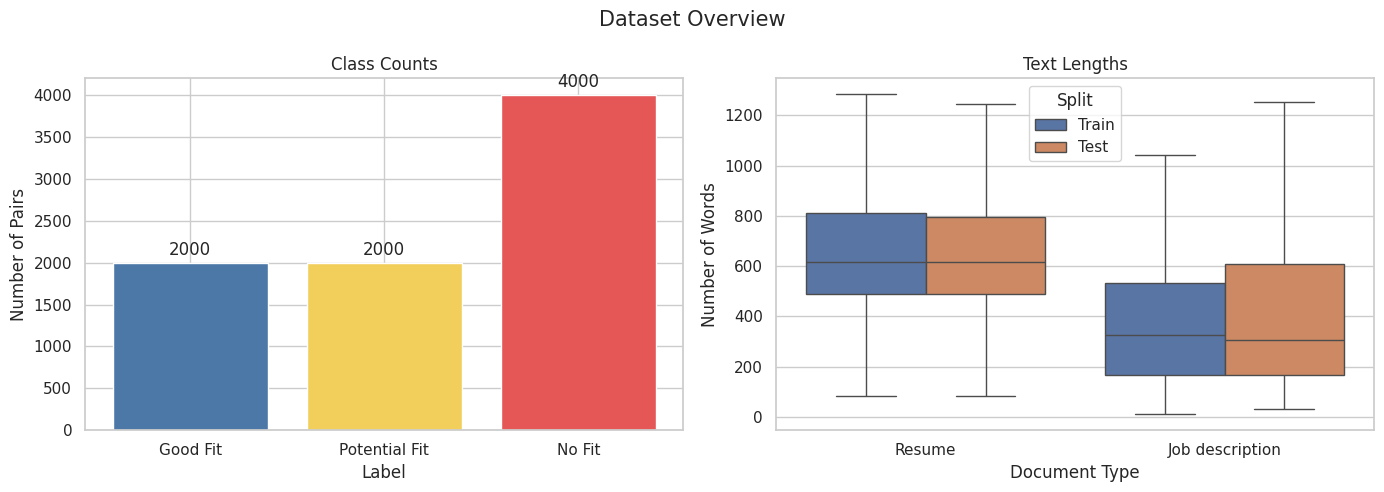

Figure saved to: m2/figures/dataset-overview.png


In [9]:
from pathlib import Path

FIGURE_DIR = Path("m2/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

total_label_counts = (
    analysis_df["label"]
    .value_counts()
    .reindex(label_order)
)

length_plot_df = analysis_df[
    ["split", "resume_words", "job_words"]
].melt(
    id_vars="split",
    var_name="document_type",
    value_name="word_count"
)

length_plot_df["document_type"] = length_plot_df["document_type"].replace({
    "resume_words": "Resume",
    "job_words": "Job description"
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars = axes[0].bar(
    total_label_counts.index,
    total_label_counts.values,
    color=["#4C78A8", "#F2CF5B", "#E45756"]
)
axes[0].bar_label(bars, padding=3)
axes[0].set_title("Class Counts")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Number of Pairs")

sns.boxplot(
    data=length_plot_df,
    x="document_type",
    y="word_count",
    hue="split",
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("Text Lengths")
axes[1].set_xlabel("Document Type")
axes[1].set_ylabel("Number of Words")
axes[1].legend(title="Split")

fig.suptitle("Dataset Overview", fontsize=15)
plt.tight_layout()

figure_path = FIGURE_DIR / "dataset-overview.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {figure_path}")

In [10]:
dataset_info = dataset["train"].info
DATASET_URL = f"https://huggingface.co/datasets/{DATASET_NAME}"

def show_metadata(value):
    if value is None or str(value).strip() == "":
        return "Not provided"
    return str(value).strip()

dataset_metadata = pd.DataFrame({
    "Value": [
        DATASET_NAME,
        DATASET_URL,
        show_metadata(dataset_info.description),
        show_metadata(dataset_info.license),
        show_metadata(dataset_info.homepage),
        show_metadata(dataset_info.citation)
    ]
}, index=[
    "Dataset name",
    "Dataset page",
    "Description",
    "Licence",
    "Homepage",
    "Citation"
])

display(dataset_metadata)

,Value
Dataset name,cnamuangtoun/resume-job-description-fit
Dataset page,https://huggingface.co/datasets/cnamuangtoun/resume-job-description-fit
Description,Not provided
Licence,Not provided
Homepage,Not provided
Citation,Not provided


## Dataset Audit Findings

The `resume-job-description-fit` dataset is publicly available on Hugging Face. It contains resume-job pairs labelled as Good Fit, Potential Fit, or No Fit.

### Dataset Structure

| Split | Rows |
|---|---:|
| Training | 6,241 |
| Test | 1,759 |
| Total | 8,000 |

The dataset contains three columns:

- `resume_text`
- `job_description_text`
- `label`

### Label Distribution

| Label | Total rows | Percentage |
|---|---:|---:|
| Good Fit | 2,000 | 25% |
| Potential Fit | 2,000 | 25% |
| No Fit | 4,000 | 50% |

The No Fit class contains half of the dataset. Macro-F1 is therefore used as the main metric so that every class receives equal importance.

### Data Quality

- No missing values were found.
- No empty text or label values were found.
- The training split contains seven duplicate resume-job groups.
- Six duplicate groups contain conflicting labels.
- One duplicate group contains the same label.
- The test split contains no duplicate resume-job pairs.

These results match the duplicate information reported in the anchor paper.

### Split Overlap

- 476 unique resumes appear in both training and test data.
- 1,758 of the 1,759 test rows use a resume that also appears in training.
- No job descriptions are shared between training and test.
- No complete resume-job pairs are shared between training and test.

There is no exact pair overlap. However, the high resume overlap means that the test split mainly checks known resumes against new job descriptions.

### Dataset Information Limitations

The Hugging Face dataset page does not provide:

- A detailed dataset description
- Licence information
- An official homepage
- A recommended citation
- Clear information about how the data was collected

The dataset is suitable for research experiments, but these missing details should be considered when interpreting the results. It should not be used to make real hiring decisions.

In [11]:
audit_checks = {
    "Training rows equal 6,241": len(train_df) == 6241,
    "Test rows equal 1,759": len(test_df) == 1759,
    "Expected columns are present": train_df.columns.tolist() == [
        "resume_text", "job_description_text", "label"
    ],
    "Expected labels are present": set(all_labels) == {
        "Good Fit", "Potential Fit", "No Fit"
    },
    "No missing or empty values": (
        missing_summary["Total affected"].sum() == 0
    ),
    "Seven training duplicate groups": len(train_duplicate_groups) == 7,
    "Six conflicting duplicate groups": (
        train_duplicate_groups["unique_labels"].gt(1).sum() == 6
    ),
    "One same-label duplicate group": (
        train_duplicate_groups["unique_labels"].eq(1).sum() == 1
    ),
    "No test duplicate groups": len(test_duplicate_groups) == 0
}

audit_results = pd.DataFrame({
    "Check": audit_checks.keys(),
    "Passed": audit_checks.values()
})

display(audit_results)

if audit_results["Passed"].all():
    print("All dataset audit checks passed.")
else:
    print("Some dataset audit checks failed. Review the results above.")

,Check,Passed
0,"Training rows equal 6,241",True
1,"Test rows equal 1,759",True
2,Expected columns are present,True
3,Expected labels are present,True
4,No missing or empty values,True
5,Seven training duplicate groups,True
6,Six conflicting duplicate groups,True
7,One same-label duplicate group,True
8,No test duplicate groups,True


All dataset audit checks passed.


---

## Preprocessing and Data Splits

This section prepares the dataset for baseline training.

The preprocessing steps are:

1. Remove conflicting duplicate pairs.
2. Keep one row from same-label duplicate pairs.
3. Convert text to lowercase.
4. Replace Markdown links with their visible text.
5. Replace emails, URLs, and phone numbers with placeholder words.
6. Remove unwanted characters.
7. Remove repeated spaces.
8. Create stratified training and validation splits using random seed 42.
9. Keep the official test split unchanged.

The expected final split sizes are:

| Split | Rows |
|---|---:|
| Training | 4,982 |
| Validation | 1,246 |
| Test | 1,759 |

In [12]:
import re

MARKDOWN_LINK_PATTERN = re.compile(r"\[([^\]]+)\]\([^)]+\)")
EMAIL_PATTERN = re.compile(
    r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
)
URL_PATTERN = re.compile(r"(?:https?://|www\.)\S+")
PHONE_PATTERN = re.compile(
    r"(?<!\w)(?:\+?\d[\d\s().-]{8,}\d)(?!\w)"
)
UNWANTED_CHARACTER_PATTERN = re.compile(r"[^a-z0-9+#.\s]")
WHITESPACE_PATTERN = re.compile(r"\s+")

def replace_phone_number(match):
    value = match.group()
    digit_count = len(re.sub(r"\D", "", value))
    return " phone " if digit_count >= 10 else value

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = MARKDOWN_LINK_PATTERN.sub(r"\1", text)
    text = EMAIL_PATTERN.sub(" email ", text)
    text = URL_PATTERN.sub(" url ", text)
    text = PHONE_PATTERN.sub(replace_phone_number, text)
    text = UNWANTED_CHARACTER_PATTERN.sub(" ", text)
    text = WHITESPACE_PATTERN.sub(" ", text)

    return text.strip()

print("Text-cleaning function created.")

Text-cleaning function created.


In [13]:
example_text = """
Contact [Jane Doe](https://example.com/profile) at Jane.Doe@example.com.
Visit www.example.com or call +1 (555) 123-4567.
Skills: C++, C#, and machine-learning.
"""

cleaned_example = clean_text(example_text)

cleaning_checks = {
    "Visible link text kept": "jane doe" in cleaned_example,
    "Email replaced": " email " in f" {cleaned_example} ",
    "URL replaced": " url " in f" {cleaned_example} ",
    "Phone replaced": " phone " in f" {cleaned_example} ",
    "C++ kept": "c++" in cleaned_example,
    "C# kept": "c#" in cleaned_example,
    "Hyphen removed": "machine-learning" not in cleaned_example
}

print("Original text:")
print(example_text.strip())

print("\nCleaned text:")
print(cleaned_example)

display(pd.DataFrame({
    "Check": cleaning_checks.keys(),
    "Passed": cleaning_checks.values()
}))

assert all(cleaning_checks.values())

Original text:
Contact [Jane Doe](https://example.com/profile) at Jane.Doe@example.com.
Visit www.example.com or call +1 (555) 123-4567.
Skills: C++, C#, and machine-learning.

Cleaned text:
contact jane doe at email . visit url or call phone . skills c++ c# and machine learning.


,Check,Passed
0,Visible link text kept,True
1,Email replaced,True
2,URL replaced,True
3,Phone replaced,True
4,C++ kept,True
5,C# kept,True
6,Hyphen removed,True


In [14]:
pair_label_counts = (
    train_df.groupby(PAIR_COLUMNS, dropna=False)["label"]
    .transform("nunique")
)

conflicting_pair_mask = pair_label_counts > 1
rows_after_conflict_removal = train_df.loc[~conflicting_pair_mask].copy()

deduplicated_train_df = (
    rows_after_conflict_removal
    .drop_duplicates(subset=PAIR_COLUMNS, keep="first")
    .reset_index(drop=True)
)

conflicting_rows_removed = int(conflicting_pair_mask.sum())
same_label_rows_removed = (
    len(rows_after_conflict_removal) - len(deduplicated_train_df)
)

duplicate_removal_summary = pd.DataFrame({
    "Item": [
        "Original training rows",
        "Conflicting rows removed",
        "Same-label duplicate rows removed",
        "Clean training rows",
        "Official test rows"
    ],
    "Count": [
        len(train_df),
        conflicting_rows_removed,
        same_label_rows_removed,
        len(deduplicated_train_df),
        len(test_df)
    ]
})

display(duplicate_removal_summary)

remaining_duplicate_groups = find_duplicate_pairs(deduplicated_train_df)
print(f"Remaining duplicate groups: {len(remaining_duplicate_groups)}")

,Item,Count
0,Original training rows,6241
1,Conflicting rows removed,12
2,Same-label duplicate rows removed,1
3,Clean training rows,6228
4,Official test rows,1759


Remaining duplicate groups: 0


In [15]:
def add_cleaned_text_columns(dataframe):
    result = dataframe.copy()

    result["resume_text_clean"] = (
        result["resume_text"].map(clean_text)
    )
    result["job_description_text_clean"] = (
        result["job_description_text"].map(clean_text)
    )

    return result

processed_train_df = add_cleaned_text_columns(deduplicated_train_df)
processed_test_df = add_cleaned_text_columns(test_df.reset_index(drop=True))

cleaning_summary = pd.DataFrame([
    {
        "Split": split_name,
        "Document": document_name,
        "Rows": len(dataframe),
        "Changed rows": (
            dataframe[original_column] != dataframe[clean_column]
        ).sum(),
        "Empty after cleaning": dataframe[clean_column].eq("").sum(),
        "Mean characters before": dataframe[original_column].str.len().mean(),
        "Mean characters after": dataframe[clean_column].str.len().mean()
    }
    for split_name, dataframe in [
        ("Train", processed_train_df),
        ("Test", processed_test_df)
    ]
    for document_name, original_column, clean_column in [
        ("Resume", "resume_text", "resume_text_clean"),
        (
            "Job description",
            "job_description_text",
            "job_description_text_clean"
        )
    ]
])

cleaning_summary[
    ["Mean characters before", "Mean characters after"]
] = cleaning_summary[
    ["Mean characters before", "Mean characters after"]
].round(1)

display(cleaning_summary)

,Split,Document,Rows,Changed rows,Empty after cleaning,Mean characters before,Mean characters after
0,Train,Resume,6228,6228,0,5798.1,5672.6
1,Train,Job description,6228,6228,0,2731.3,2679.2
2,Test,Resume,1759,1759,0,5663.3,5538.6
3,Test,Job description,1759,1759,0,2939.2,2884.4


In [16]:
text_quality_rows = []

for split_name, dataframe in [
    ("Train", processed_train_df),
    ("Test", processed_test_df)
]:
    for document_name, column in [
        ("Resume", "resume_text_clean"),
        ("Job description", "job_description_text_clean")
    ]:
        values = dataframe[column]

        text_quality_rows.append({
            "Split": split_name,
            "Document": document_name,
            "No empty text": values.ne("").all(),
            "Lowercase": values.eq(values.str.lower()).all(),
            "Allowed characters only": (
                ~values.str.contains(
                    UNWANTED_CHARACTER_PATTERN,
                    regex=True
                ).any()
            ),
            "No repeated spaces": (
                ~values.str.contains(r"\s{2,}", regex=True).any()
            ),
            "No outer spaces": values.eq(values.str.strip()).all()
        })

text_quality_checks = pd.DataFrame(text_quality_rows)
display(text_quality_checks)

assert text_quality_checks.iloc[:, 2:].all().all()
print("All cleaned-text checks passed.")

,Split,Document,No empty text,Lowercase,Allowed characters only,No repeated spaces,No outer spaces
0,Train,Resume,True,True,True,True,True
1,Train,Job description,True,True,True,True,True
2,Test,Resume,True,True,True,True,True
3,Test,Job description,True,True,True,True,True


All cleaned-text checks passed.


In [17]:
from sklearn.model_selection import train_test_split

train_core_df, validation_df = train_test_split(
    processed_train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=processed_train_df["label"]
)

train_core_df = train_core_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_final_df = processed_test_df.reset_index(drop=True)

split_sizes = pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Rows": [
        len(train_core_df),
        len(validation_df),
        len(test_final_df)
    ],
    "Expected rows": [4982, 1246, 1759]
})

split_sizes["Matches paper"] = (
    split_sizes["Rows"] == split_sizes["Expected rows"]
)

display(split_sizes)
print(f"Total cleaned rows: {split_sizes['Rows'].sum():,}")

,Split,Rows,Expected rows,Matches paper
0,Training,4982,4982,True
1,Validation,1246,1246,True
2,Test,1759,1759,True


Total cleaned rows: 7,987


In [18]:
split_dataframes = {
    "Training": train_core_df,
    "Validation": validation_df,
    "Test": test_final_df
}

split_label_counts = pd.DataFrame({
    split_name: dataframe["label"].value_counts()
    for split_name, dataframe in split_dataframes.items()
}).T.reindex(columns=label_order).fillna(0).astype(int)

split_label_counts["Total"] = split_label_counts.sum(axis=1)

expected_label_counts = pd.DataFrame(
    {
        "Good Fit": [1230, 308, 458],
        "Potential Fit": [1243, 311, 444],
        "No Fit": [2509, 627, 857],
        "Total": [4982, 1246, 1759]
    },
    index=["Training", "Validation", "Test"]
)

display(split_label_counts)

print(
    "Label counts match the paper:",
    split_label_counts.equals(expected_label_counts)
)

label,Good Fit,Potential Fit,No Fit,Total
Training,1230,1243,2509,4982
Validation,308,311,627,1246
Test,458,444,857,1759


Label counts match the paper: True


In [19]:
def get_pair_set(dataframe):
    return set(zip(
        dataframe["resume_text"],
        dataframe["job_description_text"]
    ))

def count_shared_values(first_df, second_df, column):
    return len(
        set(first_df[column]) & set(second_df[column])
    )

split_comparisons = [
    ("Training and validation", train_core_df, validation_df),
    ("Training and test", train_core_df, test_final_df),
    ("Validation and test", validation_df, test_final_df)
]

split_overlap_rows = []

for comparison, first_df, second_df in split_comparisons:
    split_overlap_rows.append({
        "Comparison": comparison,
        "Shared pairs": len(
            get_pair_set(first_df) & get_pair_set(second_df)
        ),
        "Shared resumes": count_shared_values(
            first_df, second_df, "resume_text"
        ),
        "Shared job descriptions": count_shared_values(
            first_df, second_df, "job_description_text"
        )
    })

split_overlap_summary = pd.DataFrame(split_overlap_rows)
display(split_overlap_summary)

test_columns = ["resume_text", "job_description_text", "label"]
test_is_unchanged = test_final_df[test_columns].equals(
    test_df.reset_index(drop=True)[test_columns]
)

print("Official test rows and labels unchanged:", test_is_unchanged)

,Comparison,Shared pairs,Shared resumes,Shared job descriptions
0,Training and validation,0,441,246
1,Training and test,0,473,0
2,Validation and test,0,368,0


Official test rows and labels unchanged: True


In [20]:
repeat_train_df, repeat_validation_df = train_test_split(
    processed_train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=processed_train_df["label"]
)

repeat_train_df = repeat_train_df.reset_index(drop=True)
repeat_validation_df = repeat_validation_df.reset_index(drop=True)

preprocessing_checks = {
    "Clean training data has 6,228 rows": (
        len(processed_train_df) == 6228
    ),
    "Training split has 4,982 rows": (
        len(train_core_df) == 4982
    ),
    "Validation split has 1,246 rows": (
        len(validation_df) == 1246
    ),
    "Test split has 1,759 rows": (
        len(test_final_df) == 1759
    ),
    "Label counts match the paper": (
        split_label_counts.equals(expected_label_counts)
    ),
    "No training duplicate pairs": (
        len(find_duplicate_pairs(train_core_df)) == 0
    ),
    "No validation duplicate pairs": (
        len(find_duplicate_pairs(validation_df)) == 0
    ),
    "No test duplicate pairs": (
        len(find_duplicate_pairs(test_final_df)) == 0
    ),
    "No complete pair overlap": (
        split_overlap_summary["Shared pairs"].eq(0).all()
    ),
    "Official test data is unchanged": test_is_unchanged,
    "Split is repeatable with seed 42": (
        repeat_train_df.equals(train_core_df)
        and repeat_validation_df.equals(validation_df)
    )
}

preprocessing_results = pd.DataFrame({
    "Check": preprocessing_checks.keys(),
    "Passed": preprocessing_checks.values()
})

display(preprocessing_results)

if preprocessing_results["Passed"].all():
    print("All preprocessing and split checks passed.")
else:
    print("Some checks failed. Review the results above.")

,Check,Passed
0,"Clean training data has 6,228 rows",True
1,"Training split has 4,982 rows",True
2,"Validation split has 1,246 rows",True
3,"Test split has 1,759 rows",True
4,Label counts match the paper,True
5,No training duplicate pairs,True
6,No validation duplicate pairs,True
7,No test duplicate pairs,True
8,No complete pair overlap,True
9,Official test data is unchanged,True


All preprocessing and split checks passed.


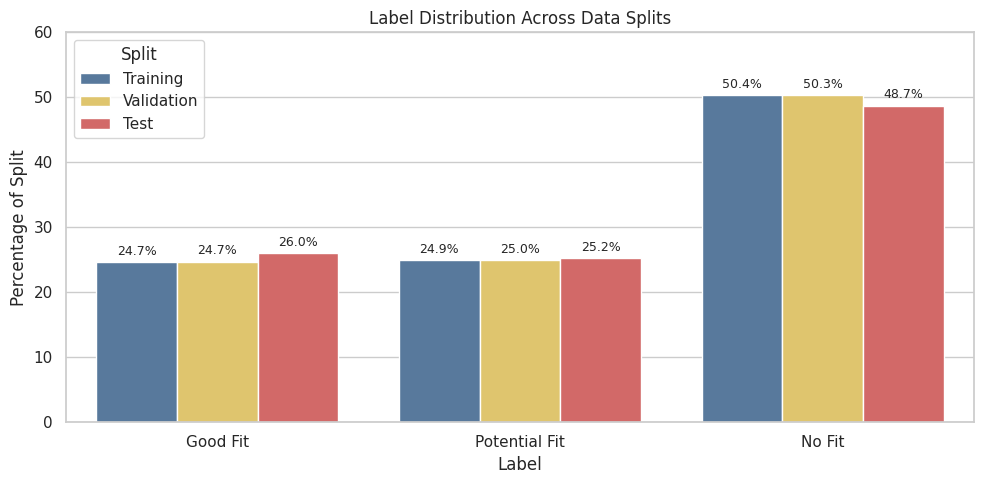

Figure saved to: m2/figures/split-label-distribution.png


In [21]:
split_label_percentages = (
    split_label_counts[label_order]
    .div(split_label_counts["Total"], axis=0)
    .mul(100)
    .round(2)
)

split_plot_df = (
    split_label_percentages
    .reset_index(names="Split")
    .melt(
        id_vars="Split",
        var_name="Label",
        value_name="Percentage"
    )
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=split_plot_df,
    x="Label",
    y="Percentage",
    hue="Split",
    palette=["#4C78A8", "#F2CF5B", "#E45756"],
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

ax.set_title("Label Distribution Across Data Splits")
ax.set_xlabel("Label")
ax.set_ylabel("Percentage of Split")
ax.set_ylim(0, 60)
ax.legend(title="Split")

plt.tight_layout()

split_figure_path = FIGURE_DIR / "split-label-distribution.png"
fig.savefig(split_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {split_figure_path}")

## Preprocessing Results

### Duplicate Handling

The original training split contained 6,241 rows.

- Six conflicting duplicate groups were removed completely.
- This removed 12 rows.
- One same-label duplicate group was reduced to one row.
- This removed one additional row.
- The final cleaned training data contains 6,228 rows.

No duplicate resume-job pairs remain after this step.

### Text Cleaning

The following steps were applied:

1. Convert text to lowercase.
2. Replace Markdown links with visible text.
3. Replace emails with `email`.
4. Replace URLs with `url`.
5. Replace phone numbers with `phone`.
6. Remove unwanted characters.
7. Keep letters, numbers, spaces, periods, plus signs, and number signs.
8. Replace repeated spaces with one space.
9. Remove spaces from the beginning and end.

No resume or job description became empty after cleaning.

The paper does not provide its exact regular expressions or placeholder words. Our implementation follows the reported steps, but this difference may affect the final result.

### Final Data Splits

The cleaned training data was divided using stratified sampling and random seed 42.

| Split | Good Fit | Potential Fit | No Fit | Total |
|---|---:|---:|---:|---:|
| Training | 1,230 | 1,243 | 2,509 | 4,982 |
| Validation | 308 | 311 | 627 | 1,246 |
| Test | 458 | 444 | 857 | 1,759 |

The split sizes and label counts exactly match the anchor paper. The split-distribution graph also shows that the class percentages remain similar across all three splits.

The original test rows and labels were kept unchanged. Cleaning was applied only to create the text used by the models.

### Split Limitation

No complete resume-job pair appears in more than one split.

However, training and validation share 441 resumes and 246 job descriptions. The test split also shares many resumes with training and validation. This happens because the paper uses a pair-level split.

The same split method is kept so that our results can be compared with the paper.

---

## TF-IDF Baseline Models

This section reproduces two baseline models from the anchor paper.

### Model 1: TF-IDF Cosine Similarity

- Create TF-IDF vectors for resumes and job descriptions.
- Calculate one cosine-similarity score for each pair.
- Select two class thresholds using validation data.
- Predict No Fit, Potential Fit, or Good Fit.

Reported test macro-F1: **0.359**

### Model 2: Paired TF-IDF with SGD

- Join each cleaned resume and job description.
- Create one TF-IDF vector for each joined pair.
- Train an SGD classifier with logistic loss.
- Predict the three fit classes directly.

Reported test macro-F1: **0.436**

The validation split will be used for model selection. The official test split will be used only after the model settings are fixed.

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score

MODEL_LABELS = ["Good Fit", "Potential Fit", "No Fit"]

def calculate_basic_metrics(true_labels, predicted_labels):
    return {
        "Macro-F1": f1_score(
            true_labels,
            predicted_labels,
            labels=MODEL_LABELS,
            average="macro",
            zero_division=0
        ),
        "Accuracy": accuracy_score(
            true_labels,
            predicted_labels
        ),
        "Weighted F1": f1_score(
            true_labels,
            predicted_labels,
            labels=MODEL_LABELS,
            average="weighted",
            zero_division=0
        )
    }

print("Baseline model tools ready.")

Baseline model tools ready.


In [23]:
similarity_training_text = pd.concat(
    [
        train_core_df["resume_text_clean"],
        train_core_df["job_description_text_clean"]
    ],
    ignore_index=True
)

similarity_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=30000,
    min_df=3,
    stop_words="english"
)

similarity_start_time = time.perf_counter()
similarity_vectorizer.fit(similarity_training_text)

validation_resume_matrix = similarity_vectorizer.transform(
    validation_df["resume_text_clean"]
)
validation_job_matrix = similarity_vectorizer.transform(
    validation_df["job_description_text_clean"]
)

validation_similarity_scores = np.asarray(
    validation_resume_matrix
    .multiply(validation_job_matrix)
    .sum(axis=1)
).ravel()

similarity_fit_time = time.perf_counter() - similarity_start_time

similarity_score_summary = pd.Series(
    validation_similarity_scores
).describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
).round(4)

print(f"Vocabulary size: {len(similarity_vectorizer.vocabulary_):,}")
print(f"Validation pairs: {len(validation_similarity_scores):,}")
print(f"Fit and validation time: {similarity_fit_time:.2f} seconds")
print("\nValidation similarity scores:")
display(similarity_score_summary.to_frame("Value"))

Vocabulary size: 30,000
Validation pairs: 1,246
Fit and validation time: 22.69 seconds

Validation similarity scores:


,Value
count,1246.0000
mean,0.0464
std,0.0336
min,0.0000
25%,0.0230
50%,0.0381
75%,0.0593
90%,0.0932
95%,0.1139
max,0.2338


In [24]:
def predict_from_similarity(scores, lower_threshold, upper_threshold):
    return np.where(
        scores < lower_threshold,
        "No Fit",
        np.where(
            scores < upper_threshold,
            "Potential Fit",
            "Good Fit"
        )
    )

threshold_grid = np.arange(0.000, 0.241, 0.005)
threshold_search_rows = []

threshold_search_start = time.perf_counter()

for lower_threshold in threshold_grid:
    for upper_threshold in threshold_grid:
        if lower_threshold >= upper_threshold:
            continue

        predictions = predict_from_similarity(
            validation_similarity_scores,
            lower_threshold,
            upper_threshold
        )

        threshold_search_rows.append({
            "Lower threshold": lower_threshold,
            "Upper threshold": upper_threshold,
            "Macro-F1": f1_score(
                validation_df["label"],
                predictions,
                labels=MODEL_LABELS,
                average="macro",
                zero_division=0
            )
        })

threshold_results = (
    pd.DataFrame(threshold_search_rows)
    .sort_values(
        ["Macro-F1", "Lower threshold", "Upper threshold"],
        ascending=[False, True, True]
    )
    .reset_index(drop=True)
)

threshold_search_time = time.perf_counter() - threshold_search_start

print(f"Threshold combinations tested: {len(threshold_results):,}")
print(f"Search time: {threshold_search_time:.2f} seconds")
print("\nBest coarse threshold combinations:")

display(threshold_results.head(10).round(4))

Threshold combinations tested: 1,176
Search time: 15.55 seconds

Best coarse threshold combinations:


,Lower threshold,Upper threshold,Macro-F1
0,0.045,0.075,0.4149
1,0.040,0.055,0.4130
2,0.040,0.075,0.4114
3,0.045,0.080,0.4110
4,0.035,0.055,0.4108
5,0.040,0.060,0.4106
6,0.045,0.070,0.4106
7,0.045,0.055,0.4104
8,0.045,0.060,0.4102
9,0.040,0.070,0.4080


In [25]:
fine_lower_grid = np.arange(0.030, 0.051, 0.001)
fine_upper_grid = np.arange(0.050, 0.086, 0.001)
fine_threshold_rows = []

for lower_threshold in fine_lower_grid:
    for upper_threshold in fine_upper_grid:
        if lower_threshold >= upper_threshold:
            continue

        predictions = predict_from_similarity(
            validation_similarity_scores,
            lower_threshold,
            upper_threshold
        )

        fine_threshold_rows.append({
            "Lower threshold": lower_threshold,
            "Upper threshold": upper_threshold,
            "Macro-F1": f1_score(
                validation_df["label"],
                predictions,
                labels=MODEL_LABELS,
                average="macro",
                zero_division=0
            )
        })

fine_threshold_results = (
    pd.DataFrame(fine_threshold_rows)
    .sort_values(
        ["Macro-F1", "Lower threshold", "Upper threshold"],
        ascending=[False, True, True]
    )
    .reset_index(drop=True)
)

best_lower_threshold = float(
    fine_threshold_results.loc[0, "Lower threshold"]
)
best_upper_threshold = float(
    fine_threshold_results.loc[0, "Upper threshold"]
)

validation_similarity_predictions = predict_from_similarity(
    validation_similarity_scores,
    best_lower_threshold,
    best_upper_threshold
)

validation_similarity_metrics = calculate_basic_metrics(
    validation_df["label"],
    validation_similarity_predictions
)

print(f"Best lower threshold: {best_lower_threshold:.3f}")
print(f"Best upper threshold: {best_upper_threshold:.3f}")
print(f"Paper validation macro-F1: 0.416")
print(
    "Reproduced validation macro-F1: "
    f"{validation_similarity_metrics['Macro-F1']:.4f}"
)

display(fine_threshold_results.head(10).round(4))

Best lower threshold: 0.045
Best upper threshold: 0.074
Paper validation macro-F1: 0.416
Reproduced validation macro-F1: 0.4174


,Lower threshold,Upper threshold,Macro-F1
0,0.045,0.074,0.4174
1,0.045,0.077,0.4174
2,0.045,0.078,0.4162
3,0.045,0.073,0.4153
4,0.038,0.055,0.4153
5,0.037,0.055,0.4153
6,0.045,0.076,0.4151
7,0.045,0.075,0.4149
8,0.038,0.057,0.4145
9,0.037,0.057,0.4143


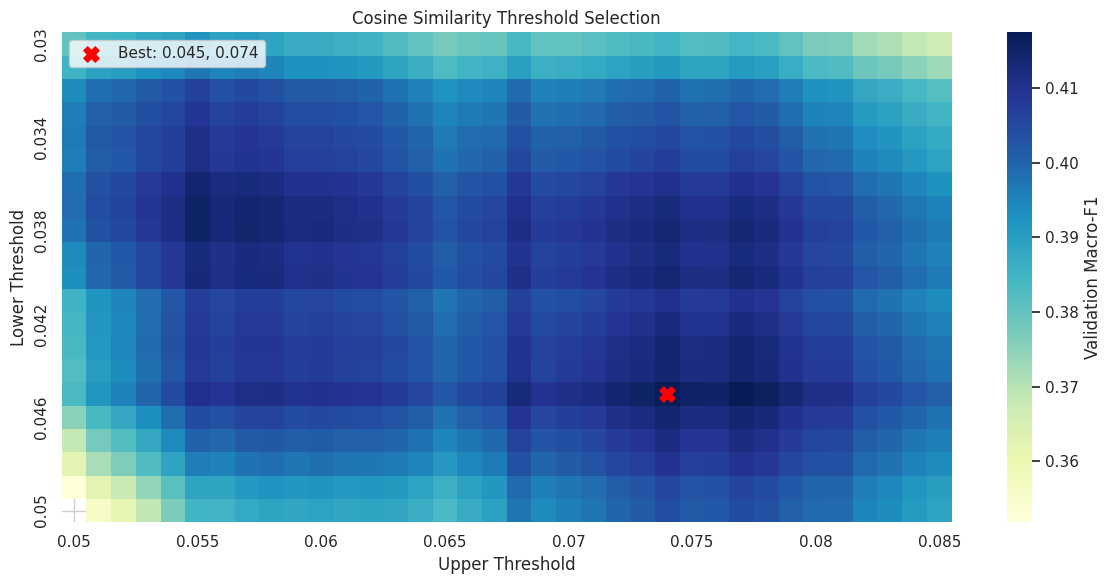

Figure saved to: m2/figures/threshold-selection.png


In [27]:
heatmap_source = fine_threshold_results.copy()
heatmap_source["Lower threshold"] = (
    heatmap_source["Lower threshold"].round(3)
)
heatmap_source["Upper threshold"] = (
    heatmap_source["Upper threshold"].round(3)
)

fine_heatmap_data = heatmap_source.pivot(
    index="Lower threshold",
    columns="Upper threshold",
    values="Macro-F1"
).sort_index(ascending=True)

best_x_position = np.argmin(
    np.abs(
        fine_heatmap_data.columns.to_numpy()
        - best_upper_threshold
    )
)
best_y_position = np.argmin(
    np.abs(
        fine_heatmap_data.index.to_numpy()
        - best_lower_threshold
    )
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    fine_heatmap_data,
    cmap="YlGnBu",
    mask=fine_heatmap_data.isna(),
    xticklabels=5,
    yticklabels=4,
    cbar_kws={"label": "Validation Macro-F1"},
    ax=ax
)

ax.scatter(
    best_x_position + 0.5,
    best_y_position + 0.5,
    color="red",
    marker="X",
    s=120,
    label=(
        f"Best: {best_lower_threshold:.3f}, "
        f"{best_upper_threshold:.3f}"
    )
)

ax.set_title("Cosine Similarity Threshold Selection")
ax.set_xlabel("Upper Threshold")
ax.set_ylabel("Lower Threshold")
ax.legend(loc="upper left")

plt.tight_layout()

threshold_figure_path = FIGURE_DIR / "threshold-selection.png"
fig.savefig(threshold_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {threshold_figure_path}")

In [28]:
similarity_test_start = time.perf_counter()

test_resume_matrix = similarity_vectorizer.transform(
    test_final_df["resume_text_clean"]
)
test_job_matrix = similarity_vectorizer.transform(
    test_final_df["job_description_text_clean"]
)

test_similarity_scores = np.asarray(
    test_resume_matrix
    .multiply(test_job_matrix)
    .sum(axis=1)
).ravel()

test_similarity_predictions = predict_from_similarity(
    test_similarity_scores,
    best_lower_threshold,
    best_upper_threshold
)

test_similarity_time = time.perf_counter() - similarity_test_start

test_similarity_metrics = calculate_basic_metrics(
    test_final_df["label"],
    test_similarity_predictions
)

similarity_metrics_table = pd.DataFrame(
    [
        validation_similarity_metrics,
        test_similarity_metrics
    ],
    index=["Validation", "Test"]
).round(4)

similarity_test_results_df = pd.DataFrame({
    "True label": test_final_df["label"],
    "Similarity score": test_similarity_scores,
    "Predicted label": test_similarity_predictions
})

display(similarity_metrics_table)

print(f"Paper test macro-F1: 0.359")
print(
    "Reproduced test macro-F1: "
    f"{test_similarity_metrics['Macro-F1']:.4f}"
)
print(f"Test evaluation time: {test_similarity_time:.2f} seconds")

,Macro-F1,Accuracy,Weighted F1
Validation,0.4174,0.496,0.4788
Test,0.3708,0.411,0.4132


Paper test macro-F1: 0.359
Reproduced test macro-F1: 0.3708
Test evaluation time: 8.24 seconds


### Paired TF-IDF with SGD

For this model, each cleaned resume and job description is joined in this form:

`resume [resume text] job [job description text]`

The TF-IDF settings are:

- Word unigrams and bigrams
- Maximum 50,000 features
- Minimum document frequency of 3
- Maximum document frequency of 0.98
- Sublinear term frequency
- English stop words

The classifier uses:

- SGD with logistic loss
- Alpha: 0.00001
- Random seed: 42

The paper reports a validation macro-F1 of 0.658 and a test macro-F1 of 0.436.

In [29]:
def create_pair_text(dataframe):
    return (
        "resume "
        + dataframe["resume_text_clean"]
        + " job "
        + dataframe["job_description_text_clean"]
    )

train_pair_text = create_pair_text(train_core_df)
validation_pair_text = create_pair_text(validation_df)
test_pair_text = create_pair_text(test_final_df)

pair_text_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Pairs": [
        len(train_pair_text),
        len(validation_pair_text),
        len(test_pair_text)
    ],
    "Mean words per pair": [
        train_pair_text.str.split().str.len().mean(),
        validation_pair_text.str.split().str.len().mean(),
        test_pair_text.str.split().str.len().mean()
    ],
    "Empty pairs": [
        train_pair_text.eq("").sum(),
        validation_pair_text.eq("").sum(),
        test_pair_text.eq("").sum()
    ]
})

pair_text_summary["Mean words per pair"] = (
    pair_text_summary["Mean words per pair"].round(1)
)

display(pair_text_summary)

assert pair_text_summary["Empty pairs"].eq(0).all()

,Split,Pairs,Mean words per pair,Empty pairs
0,Training,4982,1138.3,0
1,Validation,1246,1112.4,0
2,Test,1759,1149.5,0


In [30]:
paired_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=50000,
    min_df=3,
    max_df=0.98,
    sublinear_tf=True,
    stop_words="english"
)

paired_vectorizer_start = time.perf_counter()

train_pair_matrix = paired_vectorizer.fit_transform(
    train_pair_text
)
validation_pair_matrix = paired_vectorizer.transform(
    validation_pair_text
)

paired_vectorizer_time = (
    time.perf_counter() - paired_vectorizer_start
)

matrix_density = (
    train_pair_matrix.nnz
    / (train_pair_matrix.shape[0] * train_pair_matrix.shape[1])
    * 100
)

print(f"Vocabulary size: {len(paired_vectorizer.vocabulary_):,}")
print(f"Training matrix shape: {train_pair_matrix.shape}")
print(f"Validation matrix shape: {validation_pair_matrix.shape}")
print(f"Training matrix density: {matrix_density:.4f}%")
print(f"Vectorization time: {paired_vectorizer_time:.2f} seconds")

Vocabulary size: 50,000
Training matrix shape: (4982, 50000)
Validation matrix shape: (1246, 50000)
Training matrix density: 1.7511%
Vectorization time: 18.20 seconds


In [31]:
sgd_classifier = SGDClassifier(
    loss="log_loss",
    alpha=1e-5,
    random_state=SEED
)

sgd_training_start = time.perf_counter()

sgd_classifier.fit(
    train_pair_matrix,
    train_core_df["label"]
)

sgd_training_time = time.perf_counter() - sgd_training_start

validation_sgd_predictions = sgd_classifier.predict(
    validation_pair_matrix
)

validation_sgd_metrics = calculate_basic_metrics(
    validation_df["label"],
    validation_sgd_predictions
)

display(
    pd.DataFrame(
        [validation_sgd_metrics],
        index=["Validation"]
    ).round(4)
)

print(f"Classes: {sgd_classifier.classes_.tolist()}")
print(f"Training iterations: {sgd_classifier.n_iter_}")
print(f"Training time: {sgd_training_time:.2f} seconds")
print("Paper validation macro-F1: 0.658")
print(
    "Reproduced validation macro-F1: "
    f"{validation_sgd_metrics['Macro-F1']:.4f}"
)

,Macro-F1,Accuracy,Weighted F1
Validation,0.6513,0.6701,0.6677


Classes: ['Good Fit', 'No Fit', 'Potential Fit']
Training iterations: 49
Training time: 7.00 seconds
Paper validation macro-F1: 0.658
Reproduced validation macro-F1: 0.6513


In [32]:
sgd_test_start = time.perf_counter()

test_pair_matrix = paired_vectorizer.transform(
    test_pair_text
)

test_sgd_predictions = sgd_classifier.predict(
    test_pair_matrix
)

sgd_test_time = time.perf_counter() - sgd_test_start

test_sgd_metrics = calculate_basic_metrics(
    test_final_df["label"],
    test_sgd_predictions
)

sgd_metrics_table = pd.DataFrame(
    [
        validation_sgd_metrics,
        test_sgd_metrics
    ],
    index=["Validation", "Test"]
).round(4)

sgd_test_results_df = pd.DataFrame({
    "True label": test_final_df["label"],
    "Predicted label": test_sgd_predictions
})

display(sgd_metrics_table)

print("Paper test macro-F1: 0.436")
print(
    "Reproduced test macro-F1: "
    f"{test_sgd_metrics['Macro-F1']:.4f}"
)
print(f"Test transformation and prediction time: {sgd_test_time:.2f} seconds")

,Macro-F1,Accuracy,Weighted F1
Validation,0.6513,0.6701,0.6677
Test,0.4100,0.5088,0.4671


Paper test macro-F1: 0.436
Reproduced test macro-F1: 0.4100
Test transformation and prediction time: 9.79 seconds


In [33]:
baseline_comparison = pd.DataFrame({
    "Model": [
        "TF-IDF cosine similarity",
        "Paired TF-IDF with SGD"
    ],
    "Paper validation macro-F1": [0.416, 0.658],
    "Reproduced validation macro-F1": [
        validation_similarity_metrics["Macro-F1"],
        validation_sgd_metrics["Macro-F1"]
    ],
    "Paper test macro-F1": [0.359, 0.436],
    "Reproduced test macro-F1": [
        test_similarity_metrics["Macro-F1"],
        test_sgd_metrics["Macro-F1"]
    ],
    "Test accuracy": [
        test_similarity_metrics["Accuracy"],
        test_sgd_metrics["Accuracy"]
    ],
    "Test weighted F1": [
        test_similarity_metrics["Weighted F1"],
        test_sgd_metrics["Weighted F1"]
    ]
})

baseline_comparison["Validation gap"] = (
    baseline_comparison["Reproduced validation macro-F1"]
    - baseline_comparison["Paper validation macro-F1"]
)

baseline_comparison["Test gap"] = (
    baseline_comparison["Reproduced test macro-F1"]
    - baseline_comparison["Paper test macro-F1"]
)

display(baseline_comparison.round(4))

best_model_index = baseline_comparison[
    "Reproduced test macro-F1"
].idxmax()

print(
    "Best reproduced baseline: "
    f"{baseline_comparison.loc[best_model_index, 'Model']}"
)

,Model,Paper validation macro-F1,Reproduced validation macro-F1,Paper test macro-F1,Reproduced test macro-F1,Test accuracy,Test weighted F1,Validation gap,Test gap
0,TF-IDF cosine similarity,0.416,0.4174,0.359,0.3708,0.4110,0.4132,0.0014,0.0118
1,Paired TF-IDF with SGD,0.658,0.6513,0.436,0.4100,0.5088,0.4671,-0.0067,-0.0260


Best reproduced baseline: Paired TF-IDF with SGD


In [34]:
baseline_checks = {
    "Similarity vocabulary has 30,000 features": (
        len(similarity_vectorizer.vocabulary_) == 30000
    ),
    "Paired vocabulary has 50,000 features": (
        len(paired_vectorizer.vocabulary_) == 50000
    ),
    "Lower threshold is below upper threshold": (
        best_lower_threshold < best_upper_threshold
    ),
    "Validation similarity predictions are complete": (
        len(validation_similarity_predictions) == len(validation_df)
    ),
    "Test similarity predictions are complete": (
        len(test_similarity_predictions) == len(test_final_df)
    ),
    "Validation SGD predictions are complete": (
        len(validation_sgd_predictions) == len(validation_df)
    ),
    "Test SGD predictions are complete": (
        len(test_sgd_predictions) == len(test_final_df)
    ),
    "Similarity scores contain no invalid values": (
        np.isfinite(validation_similarity_scores).all()
        and np.isfinite(test_similarity_scores).all()
    ),
    "SGD uses logistic loss": (
        sgd_classifier.get_params()["loss"] == "log_loss"
    ),
    "SGD alpha is 0.00001": (
        sgd_classifier.get_params()["alpha"] == 1e-5
    ),
    "SGD random seed is 42": (
        sgd_classifier.get_params()["random_state"] == SEED
    ),
    "Predictions use only expected labels": (
        set(test_similarity_predictions).issubset(MODEL_LABELS)
        and set(test_sgd_predictions).issubset(MODEL_LABELS)
    )
}

baseline_check_results = pd.DataFrame({
    "Check": baseline_checks.keys(),
    "Passed": baseline_checks.values()
})

display(baseline_check_results)

if baseline_check_results["Passed"].all():
    print("All baseline model checks passed.")
else:
    print("Some baseline model checks failed.")

,Check,Passed
0,"Similarity vocabulary has 30,000 features",True
1,"Paired vocabulary has 50,000 features",True
2,Lower threshold is below upper threshold,True
3,Validation similarity predictions are complete,True
4,Test similarity predictions are complete,True
5,Validation SGD predictions are complete,True
6,Test SGD predictions are complete,True
7,Similarity scores contain no invalid values,True
8,SGD uses logistic loss,True
9,SGD alpha is 0.00001,True


All baseline model checks passed.


## Baseline Model Results

### TF-IDF Cosine Similarity

The similarity model used:

- Word unigrams and bigrams
- 30,000 maximum features
- Minimum document frequency of 3
- English stop words
- Row-wise cosine similarity

The TF-IDF vectorizer was fitted only on training text. Two class thresholds were selected using validation data.

Selected thresholds:

- Lower threshold: 0.045
- Upper threshold: 0.074

| Split | Paper macro-F1 | Reproduced macro-F1 |
|---|---:|---:|
| Validation | 0.416 | 0.4174 |
| Test | 0.359 | 0.3708 |

The reproduced test macro-F1 is 0.0118 higher than the paper result.

### Paired TF-IDF with SGD

The paired model used:

- Joined resume and job-description text
- Word unigrams and bigrams
- 50,000 maximum features
- Minimum document frequency of 3
- Maximum document frequency of 0.98
- Sublinear term frequency
- English stop words
- SGD with logistic loss
- Alpha of 0.00001
- Random seed 42

The paired TF-IDF vectorizer and SGD classifier were fitted only on training data.

| Split | Paper macro-F1 | Reproduced macro-F1 |
|---|---:|---:|
| Validation | 0.658 | 0.6513 |
| Test | 0.436 | 0.4100 |

The reproduced validation score is close to the paper. The reproduced test macro-F1 is 0.0260 lower.

### Basic Comparison

| Model | Test macro-F1 | Test accuracy | Test weighted F1 |
|---|---:|---:|---:|
| TF-IDF cosine similarity | 0.3708 | 0.4110 | 0.4132 |
| Paired TF-IDF with SGD | 0.4100 | 0.5088 | 0.4671 |

The paired TF-IDF with SGD model gives the better reproduced test result.

The test split was not used to select thresholds or train either model. Detailed class results, confusion matrices, and reproduction observations will be added during final evaluation.

---

## Detailed Evaluation and Reproduction Results

This section evaluates both reproduced baseline models in more detail.

The evaluation includes:

1. Precision, recall, and F1 for each class.
2. Confusion matrices for both models.
3. Comparison between the paper and reproduced results.
4. Explanation of the reproduction gaps.
5. Final checks that the notebook can be repeated correctly.

The official test split is used only for final evaluation. No model settings are changed after viewing the test results.

In [35]:
from sklearn.metrics import classification_report, confusion_matrix

def get_class_metrics(true_labels, predicted_labels):
    report = classification_report(
        true_labels,
        predicted_labels,
        labels=MODEL_LABELS,
        output_dict=True,
        zero_division=0
    )

    metrics = (
        pd.DataFrame(report)
        .T
        .loc[MODEL_LABELS, ["precision", "recall", "f1-score", "support"]]
    )

    metrics["support"] = metrics["support"].astype(int)
    return metrics

similarity_class_metrics = get_class_metrics(
    test_final_df["label"],
    test_similarity_predictions
)

sgd_class_metrics = get_class_metrics(
    test_final_df["label"],
    test_sgd_predictions
)

combined_class_metrics = pd.concat(
    {
        "TF-IDF cosine similarity": similarity_class_metrics,
        "Paired TF-IDF with SGD": sgd_class_metrics
    },
    names=["Model", "Class"]
)

display(combined_class_metrics.round(4))

precision  recall  f1-score  support
Model                    Class                                              
TF-IDF cosine similarity Good Fit          0.2893  0.2489    0.2676      458
                         Potential Fit     0.2638  0.3221    0.2901      444
                         No Fit            0.5662  0.5438    0.5548      857
Paired TF-IDF with SGD   Good Fit          0.5248  0.1616    0.2471      458
                         Potential Fit     0.3434  0.3063    0.3238      444
                         No Fit            0.5606  0.7993    0.6590      857

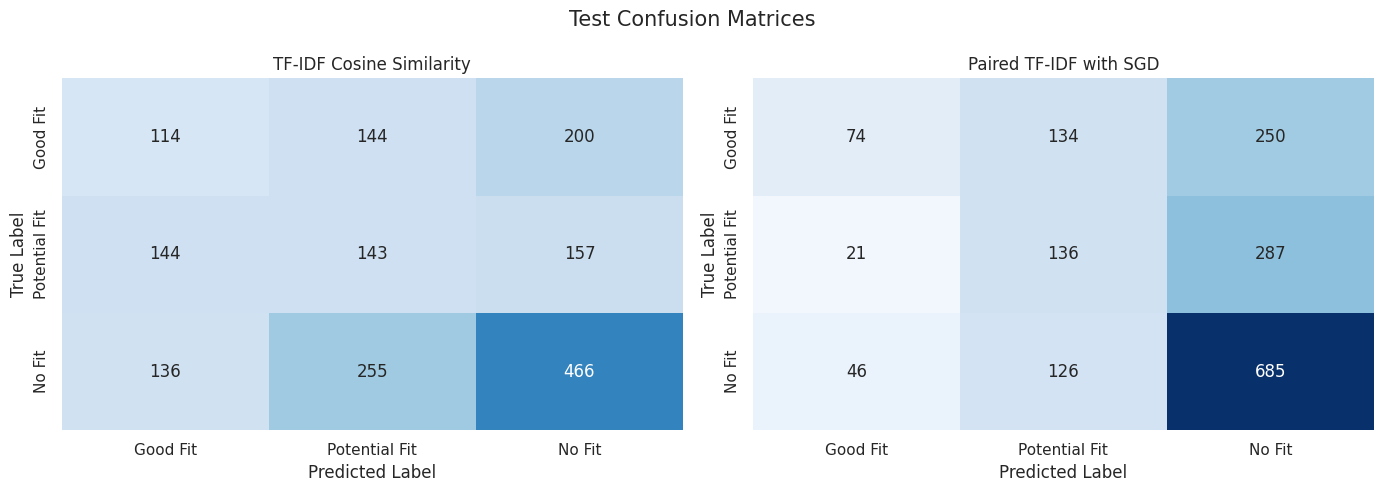

Figure saved to: m2/figures/confusion-matrices.png


In [36]:
similarity_confusion_matrix = confusion_matrix(
    test_final_df["label"],
    test_similarity_predictions,
    labels=MODEL_LABELS
)

sgd_confusion_matrix = confusion_matrix(
    test_final_df["label"],
    test_sgd_predictions,
    labels=MODEL_LABELS
)

maximum_count = max(
    similarity_confusion_matrix.max(),
    sgd_confusion_matrix.max()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, matrix, title in [
    (
        axes[0],
        similarity_confusion_matrix,
        "TF-IDF Cosine Similarity"
    ),
    (
        axes[1],
        sgd_confusion_matrix,
        "Paired TF-IDF with SGD"
    )
]:
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        vmin=0,
        vmax=maximum_count,
        cbar=False,
        xticklabels=MODEL_LABELS,
        yticklabels=MODEL_LABELS,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

fig.suptitle("Test Confusion Matrices", fontsize=15)
plt.tight_layout()

confusion_figure_path = FIGURE_DIR / "confusion-matrices.png"
fig.savefig(confusion_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {confusion_figure_path}")

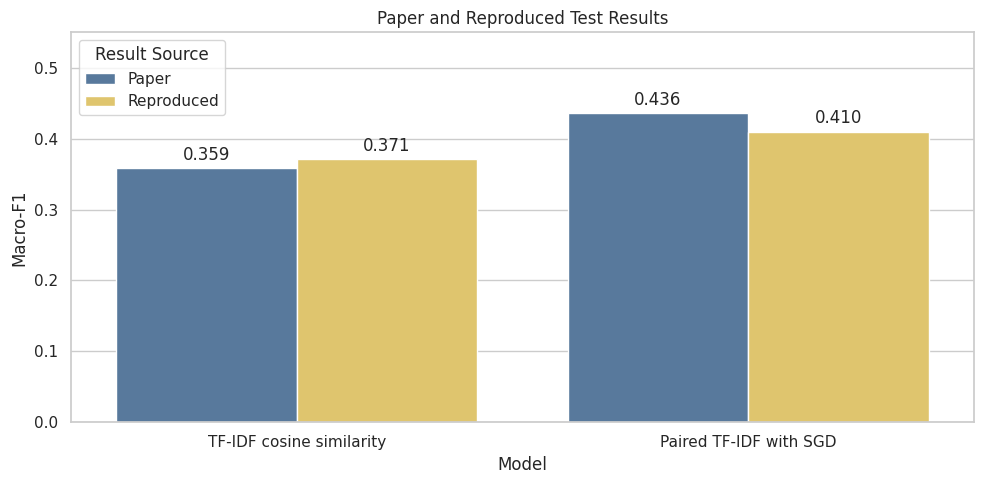

Figure saved to: m2/figures/result-comparison.png


In [37]:
result_plot_df = (
    baseline_comparison[
        [
            "Model",
            "Paper test macro-F1",
            "Reproduced test macro-F1"
        ]
    ]
    .rename(columns={
        "Paper test macro-F1": "Paper",
        "Reproduced test macro-F1": "Reproduced"
    })
    .melt(
        id_vars="Model",
        var_name="Result Source",
        value_name="Macro-F1"
    )
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=result_plot_df,
    x="Model",
    y="Macro-F1",
    hue="Result Source",
    palette=["#4C78A8", "#F2CF5B"],
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

ax.set_title("Paper and Reproduced Test Results")
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 0.55)
ax.legend(title="Result Source")

plt.tight_layout()

comparison_figure_path = FIGURE_DIR / "result-comparison.png"
fig.savefig(comparison_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {comparison_figure_path}")

In [38]:
reproduction_gap_table = baseline_comparison[
    [
        "Model",
        "Paper test macro-F1",
        "Reproduced test macro-F1"
    ]
].copy()

reproduction_gap_table["Gap"] = (
    reproduction_gap_table["Reproduced test macro-F1"]
    - reproduction_gap_table["Paper test macro-F1"]
)

reproduction_gap_table["Absolute gap"] = (
    reproduction_gap_table["Gap"].abs()
)

reproduction_gap_table["Relative gap (%)"] = (
    reproduction_gap_table["Gap"]
    / reproduction_gap_table["Paper test macro-F1"]
    * 100
)

reproduction_gap_table["Direction"] = np.where(
    reproduction_gap_table["Gap"] >= 0,
    "Higher than paper",
    "Lower than paper"
)

display(reproduction_gap_table.round(4))

,Model,Paper test macro-F1,Reproduced test macro-F1,Gap,Absolute gap,Relative gap (%),Direction
0,TF-IDF cosine similarity,0.359,0.3708,0.0118,0.0118,3.2895,Higher than paper
1,Paired TF-IDF with SGD,0.436,0.4100,-0.0260,0.0260,-5.9741,Lower than paper


In [39]:
final_figure_paths = [
    figure_path,
    split_figure_path,
    threshold_figure_path,
    confusion_figure_path,
    comparison_figure_path
]

all_test_metrics = [
    test_similarity_metrics["Macro-F1"],
    test_similarity_metrics["Accuracy"],
    test_similarity_metrics["Weighted F1"],
    test_sgd_metrics["Macro-F1"],
    test_sgd_metrics["Accuracy"],
    test_sgd_metrics["Weighted F1"]
]

final_reproduction_checks = {
    "Dataset audit checks passed": (
        audit_results["Passed"].all()
    ),
    "Preprocessing checks passed": (
        preprocessing_results["Passed"].all()
    ),
    "Baseline model checks passed": (
        baseline_check_results["Passed"].all()
    ),
    "Similarity class support equals test size": (
        similarity_class_metrics["support"].sum()
        == len(test_final_df)
    ),
    "SGD class support equals test size": (
        sgd_class_metrics["support"].sum()
        == len(test_final_df)
    ),
    "Confusion matrices equal test size": (
        similarity_confusion_matrix.sum() == len(test_final_df)
        and sgd_confusion_matrix.sum() == len(test_final_df)
    ),
    "All test metrics are valid": (
        np.isfinite(all_test_metrics).all()
    ),
    "All required figures were created": (
        all(path.exists() for path in final_figure_paths)
    ),
    "Two paper results were compared": (
        len(reproduction_gap_table) == 2
    )
}

final_check_results = pd.DataFrame({
    "Check": final_reproduction_checks.keys(),
    "Passed": final_reproduction_checks.values()
})

display(final_check_results)

if final_check_results["Passed"].all():
    print("All final reproduction checks passed.")
else:
    print("Some final reproduction checks failed.")

,Check,Passed
0,Dataset audit checks passed,True
1,Preprocessing checks passed,True
2,Baseline model checks passed,True
3,Similarity class support equals test size,True
4,SGD class support equals test size,True
5,Confusion matrices equal test size,True
6,All test metrics are valid,True
7,All required figures were created,True
8,Two paper results were compared,True


All final reproduction checks passed.


## Reproduction Observations

### Result Comparison

| Model | Paper test macro-F1 | Reproduced test macro-F1 | Gap |
|---|---:|---:|---:|
| TF-IDF cosine similarity | 0.359 | 0.3708 | +0.0118 |
| Paired TF-IDF with SGD | 0.436 | 0.4100 | -0.0260 |

The reproduced cosine baseline is slightly higher than the paper result. The reproduced SGD baseline is lower than the paper result.

Both reproductions keep the same main pattern reported in the paper: paired TF-IDF with SGD performs better than cosine similarity.

### Class-Level Results

The No Fit class is the easiest class for both models.

For cosine similarity:

- Good Fit F1: 0.2676
- Potential Fit F1: 0.2901
- No Fit F1: 0.5548

For paired TF-IDF with SGD:

- Good Fit F1: 0.2471
- Potential Fit F1: 0.3238
- No Fit F1: 0.6590

The SGD model correctly identifies many No Fit pairs, but it predicts No Fit too often. It predicts 250 Good Fit rows and 287 Potential Fit rows as No Fit. This reduces macro-F1.

### Possible Reasons for the Reproduction Gaps

1. The paper does not provide its exact text-cleaning regular expressions.
2. The paper does not provide the exact placeholder words for emails, URLs, and phone numbers.
3. The exact cosine threshold-search method is not reported.
4. Some SGD settings are not reported, so library defaults were used.
5. The paper and Colab use different package versions.
6. Small implementation differences can change sparse TF-IDF features.
7. The online dataset may have changed since the paper experiments were run.

### Environment Difference

The paper reports scikit-learn 1.8.0. The Colab environment used scikit-learn 1.6.1. Differences in default behaviour or numerical operations may affect the SGD result.

### Data Limitations

The official split contains many repeated resumes across training, validation, and test data. The split therefore does not fully measure performance on completely new resumes.

The dataset page also does not provide clear licence, collection, or citation information. The results should be treated as an academic experiment and should not be used for real hiring decisions.

## M2 Summary

This milestone reproduced two baseline models from the anchor paper using the public `resume-job-description-fit` dataset.

### Completed Work

- Documented the dataset and label distribution.
- Checked missing values, duplicates, and split overlap.
- Removed conflicting and repeated duplicate pairs.
- Implemented the reported text-cleaning steps.
- Created reproducible training and validation splits with seed 42.
- Reproduced TF-IDF with cosine similarity.
- Reproduced paired TF-IDF with an SGD classifier.
- Reported overall and per-class metrics.
- Created confusion matrices and result-comparison graphs.
- Compared the paper results with the reproduced results.
- Recorded possible reasons for the reproduction gaps.

### Final Test Results

| Model | Macro-F1 | Accuracy | Weighted F1 |
|---|---:|---:|---:|
| TF-IDF cosine similarity | 0.3708 | 0.4110 | 0.4132 |
| Paired TF-IDF with SGD | 0.4100 | 0.5088 | 0.4671 |

The paired TF-IDF with SGD model gives the better result. However, it predicts No Fit too often and performs poorly on Good Fit.

The official test split was not used for training, threshold selection, or model setting selection. It was used only for final evaluation.

The reproduction is complete, but the reported and reproduced results are not exactly equal. The differences are clearly recorded instead of being hidden.